In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ( classification_report, accuracy_score, roc_auc_score, 
                               confusion_matrix, ConfusionMatrixDisplay )
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

sns.set_theme(style="whitegrid")

In [105]:
# Chargement des données
df = pd.read_csv('student_dataset.csv')
df_raw  = df.copy() # pour garder la version brute

In [106]:
# Infos générales
print("Dimensions du dataset :", df.shape)
print("\n--- Informations sur les colonnes ---")
df.info()

Dimensions du dataset : (10245, 13)

--- Informations sur les colonnes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10245 entries, 0 to 10244
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     10245 non-null  int64  
 1   time_on_site            10245 non-null  object 
 2   pages_viewed            10245 non-null  int64  
 3   device                  10245 non-null  object 
 4   country                 10245 non-null  object 
 5   previous_purchases      10245 non-null  int64  
 6   avg_basket              10194 non-null  object 
 7   is_logged_in            10245 non-null  int64  
 8   referral                10245 non-null  object 
 9   last_action_time        10245 non-null  object 
 10  discount_used           10245 non-null  int64  
 11  session_value_estimate  10245 non-null  float64
 12  purchase                10245 non-null  int64  
dtypes: float64(1), i

In [107]:
# Aperçu
display(df.head())
display(df.sample(5, random_state=42))

,age,time_on_site,pages_viewed,device,country,previous_purchases,avg_basket,is_logged_in,referral,last_action_time,discount_used,session_value_estimate,purchase
0,54,10.026254101384902,8,tablet,FR,1,85.73682118208387,0,social,10.026254101384902,0,0.000000,0
1,67,22.928722423121496,2,desktop,US,5,58.81377720637099,0,seo,22.928722423121496,0,0.000000,0
2,44,9.774847882078312,4,tablet,DE,1,34.63993314265079,1,ads,9.774847882078312,0,0.000000,0
3,30,1.4389911715966583,18,tablet,DE,1,51.31181510939566,0,social,1.4389911715966583,0,0.000000,0
4,58,1.2302681228008607,13,mobile,FR,2,32.06346765446263,1,ads,15.496574674498959,1,73.146865,1


,age,time_on_site,pages_viewed,device,country,previous_purchases,avg_basket,is_logged_in,referral,last_action_time,discount_used,session_value_estimate,purchase
590,18,11.91920501106045,11,desktop,ES,3,65.24665753078149,0,ads,11.91920501106045,0,0.000000,0
6462,28,12.55273007150291,4,mobile,ES,1,39.7410198231495,1,direct,12.55273007150291,0,0.000000,0
8943,38,25.164499068233308,8,desktop,MA,2,54.672712821479834,0,direct,25.164499068233308,0,0.000000,0
3707,66,4.4497830990953355,19,mobile,MA,0,52.90283103708783,1,social,13.138787156173901,0,51.206248,1
5011,49,24.39996668876507,5,tablet,MA,2,31.47983771510863,0,social,24.39996668876507,0,0.000000,0


In [108]:
# Statistiques
display(df.describe(include='all'))

,age,time_on_site,pages_viewed,device,country,previous_purchases,avg_basket,is_logged_in,referral,last_action_time,discount_used,session_value_estimate,purchase
count,10245.000000,10245,10245.000000,10245,10245,10245.000000,10194,10245.000000,10245,10245,10245.000000,10245.000000,10245.000000
unique,NaN,9995,NaN,8,7,NaN,9947,NaN,8,9999,NaN,NaN,NaN
top,NaN,,NaN,desktop,US,NaN,,NaN,social,,NaN,NaN,NaN
freq,NaN,6,NaN,3443,2134,NaN,4,NaN,2575,4,NaN,NaN,NaN
mean,42.705417,NaN,10.021962,NaN,NaN,1.997950,NaN,0.498780,NaN,NaN,0.150415,21.767066,0.218058
std,15.822704,NaN,5.461806,NaN,NaN,1.410999,NaN,0.500023,NaN,NaN,0.357495,43.341550,0.412947
min,-5.000000,NaN,1.000000,NaN,NaN,0.000000,NaN,0.000000,NaN,NaN,0.000000,0.000000,0.000000
25%,29.000000,NaN,5.000000,NaN,NaN,1.000000,NaN,0.000000,NaN,NaN,0.000000,0.000000,0.000000
50%,43.000000,NaN,10.000000,NaN,NaN,2.000000,NaN,0.000000,NaN,NaN,0.000000,0.000000,0.000000
75%,56.000000,NaN,15.000000,NaN,NaN,3.000000,NaN,1.000000,NaN,NaN,0.000000,0.000000,0.000000


Avant toute préparation, on vérifie la présence de doublons et de valeurs manquantes afin d'identifier les premiers problèmes de qualité.

In [109]:
print("Nombre de doublons :", df.duplicated().sum())
 
print("\nShape avant suppression :", df.shape)
df = df.drop_duplicates()
print("Shape après suppression :", df.shape)

Nombre de doublons : 238

Shape avant suppression : (10245, 13)
Shape après suppression : (10007, 13)


In [110]:
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())


Valeurs manquantes par colonne :
age                        0
time_on_site               0
pages_viewed               0
device                     0
country                    0
previous_purchases         0
avg_basket                50
is_logged_in               0
referral                   0
last_action_time           0
discount_used              0
session_value_estimate     0
purchase                   0
dtype: int64


##  Analyse exploratoire (EDA)

In [111]:
print(df['purchase'].value_counts(normalize=True))

purchase
0    0.781853
1    0.218147
Name: proportion, dtype: float64


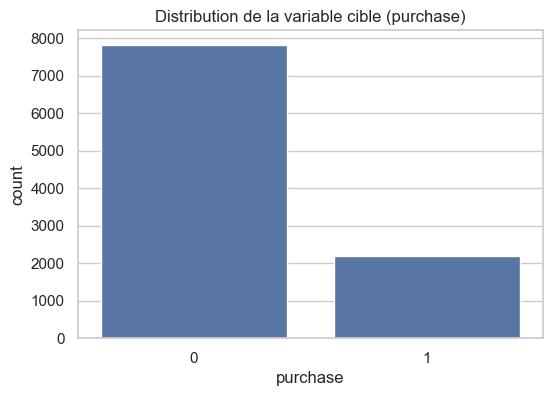

In [112]:
plt.figure(figsize=(6, 4))
sns.countplot(x='purchase', data=df)
plt.title("Distribution de la variable cible (purchase)")
plt.show()

##  Préparation des données

###  Nettoyage des variables catégorielles

In [113]:
# Supprimer les âges négatifs ou trop élevés
df = df[(df['age'] > 0) & (df['age'] < 100)]

In [114]:
for col in ['device', 'referral']:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))  #inclut aussi les NaN


--- device ---
device
desktop           3367
tablet            3336
mobile            3272
tablette            17
                     2
TOTOTOTOT            1
tablettetete         1
tablettetetete       1
Name: count, dtype: int64

--- referral ---
referral
social      2522
seo         2490
ads         2486
direct      2473
Directe       20
               4
TOTO           1
Directee       1
Name: count, dtype: int64


In [115]:
# corrige les incohérences de saisie
# 1. Correction de 'device' (mapping des fautes)
device_mapping = {
    'tablette': 'tablet',
    'tablettetete': 'tablet',
    'tablettetetete': 'tablet' ,
    'totototot' : 'unknown'
}


# 2. Normalisation de la casse
df['device'] = df['device'].str.lower().str.strip()

df['device'] = df['device'].replace(device_mapping)

# =====================================================

#  Correction de 'referral' (mapping des fautes)
referral_mapping = {
    'directe': 'direct',
    'directee': 'direct',
    'toto': 'unknown' 
}

#  Normalisation
df['referral'] = df['referral'].str.lower().str.strip()

df['referral'] = df['referral'].replace(referral_mapping)

# Vérification finale
print("Valeurs uniques après correction :")
print(f"device : {df['device'].unique()}")
print(f"referral : {df['referral'].unique()}")

Valeurs uniques après correction :
device : ['tablet' 'desktop' 'mobile' '' 'unknown']
referral : ['social' 'seo' 'ads' 'direct' '' 'unknown']


In [116]:
#Supprimer unknown et chaine vide
df = df[
    (df['device'] != 'unknown') & (df['device'].str.strip() != '') &
    (df['referral'] != 'unknown') & (df['referral'].str.strip() != '')
]

In [117]:
print(df.columns)

Index(['age', 'time_on_site', 'pages_viewed', 'device', 'country',
       'previous_purchases', 'avg_basket', 'is_logged_in', 'referral',
       'last_action_time', 'discount_used', 'session_value_estimate',
       'purchase'],
      dtype='object')


In [118]:
print(df['device'].value_counts())
print('===================')
print(df['referral'].value_counts())
print('===================')


device
desktop    3365
tablet     3354
mobile     3270
Name: count, dtype: int64
referral
social    2521
direct    2494
seo       2490
ads       2484
Name: count, dtype: int64


In [119]:
print(df.shape)

(9989, 13)


## Feature Engineering

In [120]:
# Conversion des colonnes en numeriques
df = pd.get_dummies(df, columns=['device', 'referral', 'country'], drop_first=True)

In [121]:
print(df['last_action_time'].head())

0    10.026254101384902
1    22.928722423121496
2     9.774847882078312
3    1.4389911715966583
4    15.496574674498959
Name: last_action_time, dtype: object


In [122]:
# Conversion en float
cols_to_fix = ['time_on_site', 'avg_basket', 'last_action_time']
for col in cols_to_fix:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[cols_to_fix] = df[cols_to_fix].fillna(df[cols_to_fix].median())

# 4️⃣ Vérification
print(df[cols_to_fix].dtypes)

time_on_site        float64
avg_basket          float64
last_action_time    float64
dtype: object


In [123]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

In [124]:
df['country_USA'] = df['country_USA'] + df['country_US']
df = df.drop(columns=['country_US'])

In [125]:
# Infos générales
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 9989 entries, 0 to 10044
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     9989 non-null   int64  
 1   time_on_site            9989 non-null   float64
 2   pages_viewed            9989 non-null   int64  
 3   previous_purchases      9989 non-null   int64  
 4   avg_basket              9989 non-null   float64
 5   is_logged_in            9989 non-null   int64  
 6   last_action_time        9989 non-null   float64
 7   discount_used           9989 non-null   int64  
 8   session_value_estimate  9989 non-null   float64
 9   purchase                9989 non-null   int64  
 10  device_mobile           9989 non-null   int64  
 11  device_tablet           9989 non-null   int64  
 12  referral_direct         9989 non-null   int64  
 13  referral_seo            9989 non-null   int64  
 14  referral_social         9989 non-null   int6

In [126]:
display(df.describe(include='all'))

,age,time_on_site,pages_viewed,previous_purchases,avg_basket,is_logged_in,last_action_time,discount_used,session_value_estimate,purchase,device_mobile,device_tablet,referral_direct,referral_seo,referral_social,country_DE,country_ES,country_FR,country_MA,country_USA
count,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000
mean,42.628892,10.006795,10.023526,1.998298,50.059743,0.498949,12.180287,0.150265,21.801720,0.218140,0.327360,0.335769,0.249675,0.249274,0.252378,0.195115,0.206828,0.195715,0.193513,0.208730
std,15.560794,10.002321,5.458471,1.411342,20.083618,0.500024,11.462390,0.357349,43.393337,0.413004,0.469273,0.472282,0.432846,0.432615,0.434398,0.396309,0.405051,0.396770,0.395071,0.406421
min,16.000000,0.001187,1.000000,0.000000,-28.891871,0.000000,0.001187,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,2.979428,5.000000,1.000000,36.634386,0.000000,3.627596,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,6.984213,10.000000,2.000000,50.195025,0.000000,9.055502,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,56.000000,13.687859,15.000000,3.000000,63.419498,1.000000,17.334215,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,69.000000,91.395717,19.000000,10.000000,127.132603,1.000000,101.054285,1.000000,149.823504,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Analyse des corrélations

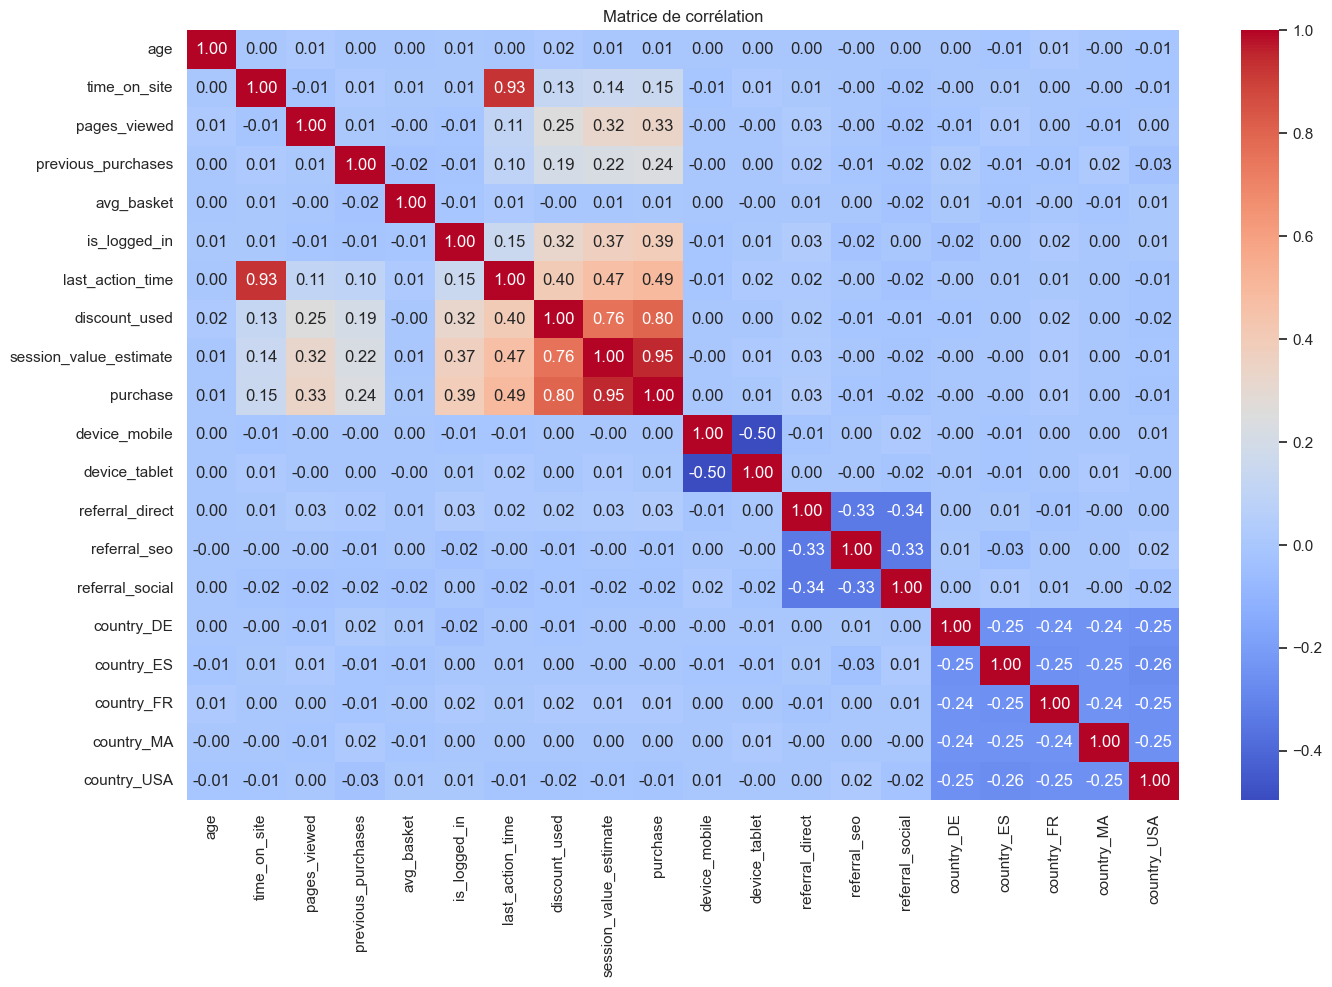

Corrélations avec la cible :


,corr_with_target
purchase,1.000000
session_value_estimate,0.951232
discount_used,0.796131
last_action_time,0.488263
is_logged_in,0.392114
pages_viewed,0.334363
previous_purchases,0.240078
time_on_site,0.148444
referral_direct,0.031900
country_FR,0.013769


In [127]:
corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(16, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

print("Corrélations avec la cible :")
display(corr["purchase"].sort_values(ascending=False).to_frame("corr_with_target"))


## Modélisation

In [1]:
def build_pipeline(X):
    # Sélection des colonnes numériques (int, float)
    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    
    # Sélection des colonnes catégorielles (object, category)
    categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

    # Pipeline pour les variables numériques
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),  # Remplace les valeurs manquantes par la médiane
        ("scaler", StandardScaler())  # Standardisation (moyenne=0, variance=1)
    ])

    # Pipeline pour les variables catégorielles
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),  # Remplace les NaN par la modalité la plus fréquente
        ("onehot", OneHotEncoder(handle_unknown="ignore"))  # Encodage one-hot (ignore les nouvelles catégories)
    ])

    # Combine les transformations numériques et catégorielles
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),  # Applique le pipeline numérique aux colonnes numériques
            ("cat", categorical_transformer, categorical_features)  # Applique le pipeline catégoriel aux colonnes catégorielles
        ]
    )

    # Définition du modèle de régression logistique
    model = LogisticRegression(max_iter=2000, class_weight="balanced")
    # max_iter=2000 → assure la convergence
    # class_weight="balanced" → gère le déséquilibre des classes

    # Pipeline global : preprocessing + modèle
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),  # Étape 1 : transformation des données
        ("model", model)  # Étape 2 : apprentissage du modèle
    ])

    # Retourne le pipeline + les listes de variables pour analyse/debug
    return pipeline, numeric_features, categorical_features

In [129]:
def evaluate_feature_set(df_model, drop_cols=None):
    # Si aucune colonne à supprimer n'est fournie, on initialise avec une liste vide
    drop_cols = drop_cols or []
    
    # Séparation des features (X) et de la cible (y)
    # On enlève la variable cible + éventuellement certaines colonnes (ex: test de feature importance)
    X = df_model.drop(columns=["target_risk"] + drop_cols)
    y = df_model["target_risk"]

    # Construction du pipeline (préprocessing + modèle)
    pipeline, num_cols, cat_cols = build_pipeline(X)

    # Split train/test  
    # test_size=0.2 → 20% des données pour le test
    # random_state=42 → reproductibilité
    # stratify=y → conserve la proportion des classes dans train et test
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Entraînement du pipeline (préprocessing + modèle)
    pipeline.fit(X_train, y_train)

    # Prédictions sur le jeu de test
    y_pred = pipeline.predict(X_test)  # prédictions de classe (0/1)
    
    # Probabilités associées à la classe positive (nécessaire pour ROC AUC)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Calcul des métriques
    accuracy = accuracy_score(y_test, y_pred)  # proportion de bonnes prédictions
    roc_auc = roc_auc_score(y_test, y_proba)  # capacité du modèle à discriminer les classes

    # Dictionnaire de résultats
    results = {
        "n_features_before_encoding": X.shape[1],  # nombre de variables avant encodage
        "numeric_features": num_cols,  # liste des variables numériques
        "categorical_features": cat_cols,  # liste des variables catégorielles
        "accuracy": accuracy,  # performance accuracy
        "roc_auc": roc_auc  # performance ROC AUC
    }

    # Retour des résultats pour analyse/comparaison
    return results

--------------------------------------------------------------------

In [136]:
# --- ÉTAPE DE NETTOYAGE MANUEL ---
# On exclut explicitement les deux variables qui causent le leakage
vars_a_exclure = ['session_value_estimate', 'discount_used']

print(f"Variables exclues pour un test réel : {vars_a_exclure}")

# 1. Préparation de X sans la cible et sans les variables de fuite
X = df.drop(columns=['purchase'] + vars_a_exclure)
y = df['purchase']

# 2. Mise à jour des listes de features pour le pipeline
# Il faut retirer 'discount_used' de la liste des catégorielles
numeric_features = ['age', 'time_on_site', 'pages_viewed', 'previous_purchases', 'avg_basket', 'last_action_time']
categorical_features = ['device', 'country', 'referral', 'is_logged_in']

# 3. Split des données
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Reconstruction du pipeline sur le nouveau X
# (On s'assure que build_pipeline prend bien en compte les nouvelles listes)
pipeline, _, _ = build_pipeline(X)

# 5. Nouvel entraînement
pipeline.fit(X_train, y_train)

# 6. Évaluation finale
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

print("\n--- RÉSULTATS DU MODÈLE RÉEL ---")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("ROC AUC  :", round(roc_auc_score(y_test, y_proba), 4))
print("\nClassification Report :")
print(classification_report(y_test, y_pred))

Variables exclues pour un test réel : ['session_value_estimate', 'discount_used']

--- RÉSULTATS DU MODÈLE RÉEL ---
Accuracy : 1.0
ROC AUC  : 1.0

Classification Report :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1562
           1       1.00      1.00      1.00       436

    accuracy                           1.00      1998
   macro avg       1.00      1.00      1.00      1998
weighted avg       1.00      1.00      1.00      1998



In [131]:
USE_RISK_INDEX = True  # mettre False pour entraîner sans cette variable

drop_cols = []
if not USE_RISK_INDEX:
    drop_cols.append("session_value_estimate")

X = df.drop(columns=["purchase"] + drop_cols)
y = df["purchase"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

pipeline, numeric_features, categorical_features = build_pipeline(X)

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("ROC AUC  :", round(roc_auc_score(y_test, y_proba), 4))
print("\nClassification report")
print(classification_report(y_test, y_pred))

Accuracy : 1.0
ROC AUC  : 1.0

Classification report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1562
           1       1.00      1.00      1.00       436

    accuracy                           1.00      1998
   macro avg       1.00      1.00      1.00      1998
weighted avg       1.00      1.00      1.00      1998



In [132]:

# 1. Séparation X et y
X = df.drop('purchase', axis=1)
y = df['purchase']

# 2. Division du dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Mise à l'échelle (SCALING) - C'est l'étape cruciale pour supprimer l'erreur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Entraînement sur les données mises à l'échelle
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# 5. Prédictions
y_pred = model.predict(X_test_scaled)

In [133]:
result = pd.DataFrame({'Actual' : y_test, 'Predicted' : y_pred})
print(result)

      Actual  Predicted
5854       1          1
3069       0          0
8763       0          0
2674       0          0
35         0          0
...      ...        ...
3216       0          0
6224       1          1
9973       1          1
172        0          0
2734       0          0

[1998 rows x 2 columns]


In [134]:
from sklearn.neighbors import KNeighborsClassifier

# On choisit k=5 comme point de départ
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Prédictions k-NN
y_pred_knn = knn_model.predict(X_test_scaled)

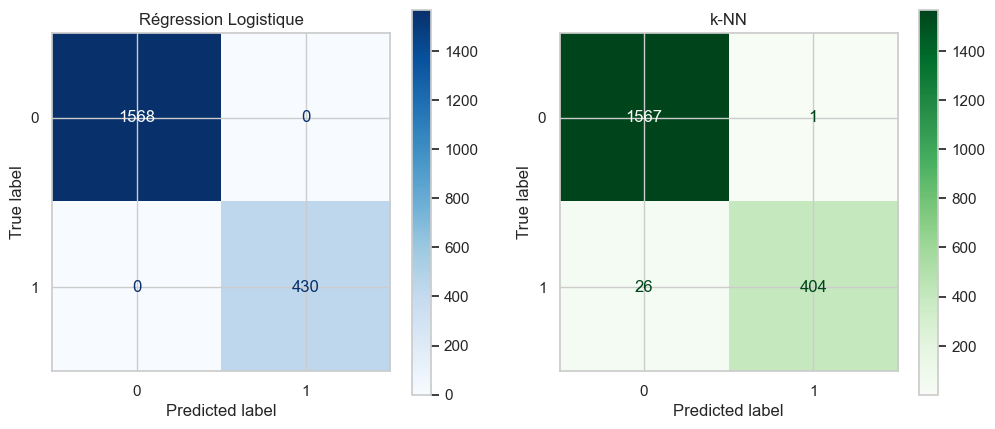

In [135]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax[0], cmap='Blues')
ax[0].set_title("Régression Logistique")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, ax=ax[1], cmap='Greens')
ax[1].set_title("k-NN")

plt.show()

In [98]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Régression Logistique": y_pred, # y_pred vient de ta cellule précédente
    "k-NN (k=5)": y_pred_knn
}

performance_data = []

for name, preds in models.items():
    performance_data.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Précision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

# Affichage du tableau de comparaison
df_compare = pd.DataFrame(performance_data)
print(df_compare)

                  Modèle  Accuracy  Précision    Recall  F1-Score
0  Régression Logistique  1.000000   1.000000  1.000000  1.000000
1             k-NN (k=5)  0.986486   0.997531  0.939535  0.967665


## Évaluation

In [99]:
print(f"Nouvelle Accuracy : {accuracy_score(y_test, y_pred):.2f}")
print(classification_report(y_test, y_pred))

Nouvelle Accuracy : 1.00
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1568
           1       1.00      1.00      1.00       430

    accuracy                           1.00      1998
   macro avg       1.00      1.00      1.00      1998
weighted avg       1.00      1.00      1.00      1998

